# Forecasting Daily Transit Ridership: Linear Regression vs. Gradient Boosting

**Question:** Can a gradient-boosted model forecast daily subway ridership one week ahead more accurately than a linear regression, and do either of them beat the simple "same weekday last week / last year" baselines that analysts often use?

**Data:** [MTA Daily Ridership and Traffic: Beginning 2020](https://data.ny.gov/d/sayj-mze2) (NY Open Data). Daily system-wide ridership estimates by mode; this notebook uses the `Subway` mode.

**Approach**
1. Load and validate the daily series.
2. Define two non-ML baselines: same weekday last week, and same weekday one year ago (52 weeks).
3. Build calendar, holiday, and lag features. Every lag is at least 7 days old, so the model only uses information that would exist when a one-week-ahead forecast is made.
4. Compare `LinearRegression` and `HistGradientBoostingRegressor` with walk-forward cross-validation, then on a final holdout of the most recent 90 days.
5. Look at where the models fail (holidays) and which features matter.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- Configuration -------------------------------------------------------
DATA_URL = "https://data.ny.gov/api/views/sayj-mze2/rows.csv?accessType=DOWNLOAD"
DATA_PATH = Path(os.environ.get("RIDERSHIP_CSV", "data/mta_daily_ridership.csv"))
OUT_DIR = Path("outputs")

MODE = "Subway"
MODEL_START = "2023-01-01"   # skip the 2020-2021 pandemic regime; lags still reach back before this date
HORIZON = 7                  # forecast one week ahead
HOLDOUT_DAYS = 90            # final test window (most recent days)
CV_SPLITS, CV_TEST_DAYS = 5, 60
RANDOM_STATE = 42

OUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Load and validate the data
The CSV is downloaded once and cached in `data/`. It is long-format (`Date`, `Mode`, `Count`) with one row per mode per day.

In [2]:
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading dataset from NY Open Data ...")
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

raw = pd.read_csv(DATA_PATH)
print(raw.shape)
print("Modes:", sorted(raw["Mode"].dropna().unique()))
raw.head()

(18145, 3)
Modes: ['AAR', 'BT', 'Bus', 'CBD Entries', 'CRZ Entries', 'LIRR', 'MNR', 'SIR', 'Subway']


,Date,Mode,Count
0,03/01/2020,AAR,19922.0
1,03/01/2020,BT,711929.0
2,03/01/2020,Bus,984908.0
3,03/01/2020,LIRR,86790.0
4,03/01/2020,MNR,55825.0


Subway: 2020-03-01 to 2026-10-06 (2,411 days), missing days: 0
Remaining missing after short-gap interpolation: 0


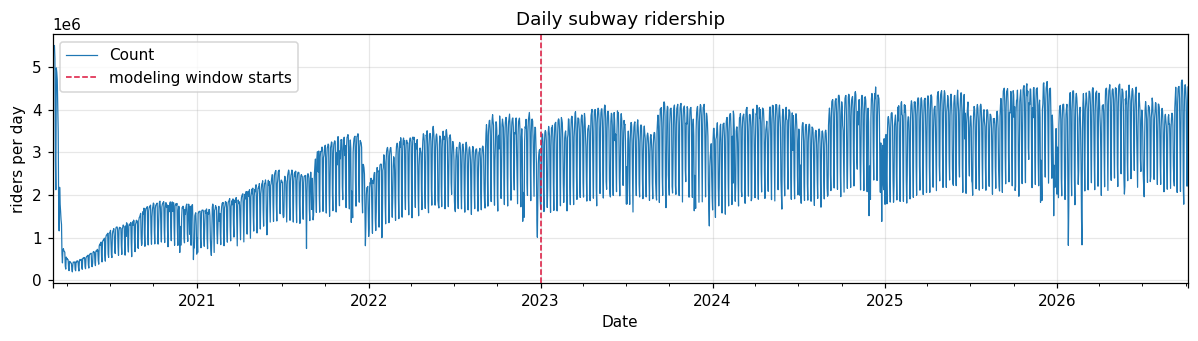

In [3]:
raw["Date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")

series = (
    raw.loc[raw["Mode"] == MODE]
       .drop_duplicates("Date")
       .set_index("Date")["Count"]
       .sort_index()
       .astype(float)
       .asfreq("D")          # enforce a continuous daily index so lags are exact calendar offsets
)

n_missing = int(series.isna().sum())
print(f"{MODE}: {series.index.min().date()} to {series.index.max().date()} "
      f"({len(series):,} days), missing days: {n_missing}")

# Fill only short gaps; anything longer stays NaN and is dropped later.
series = series.interpolate(limit=3)
print("Remaining missing after short-gap interpolation:", int(series.isna().sum()))

ax = series.plot(figsize=(11, 3.2), lw=0.8, title=f"Daily {MODE.lower()} ridership")
ax.axvline(pd.Timestamp(MODEL_START), color="crimson", ls="--", lw=1, label="modeling window starts")
ax.set_ylabel("riders per day"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "series_overview.png", dpi=150); plt.show()

## 2. Features
Weekday and holiday effects dominate daily ridership, and the level drifts over time, so the features capture three things: **calendar** (weekday, month, day-of-year), **holidays** (federal holidays and the days around them), and **recent history** (lags and a rolling mean).

All lag features are at least `HORIZON` days old, so there is no leakage from information that would not be available at forecast time. `lag_364` is the same weekday 52 weeks earlier, which acts as a prior-year baseline.

In [4]:
def build_features(y: pd.Series, horizon: int = HORIZON) -> pd.DataFrame:
    lags = (7, 14, 28, 364)
    assert min(lags) >= horizon, "lags must be at least `horizon` days old to avoid leakage"

    df = pd.DataFrame({"y": y})
    for lag in lags:
        df[f"lag_{lag}"] = y.shift(lag)
    df["roll_mean_28"] = y.shift(horizon).rolling(28).mean()

    idx = df.index
    df["dow"] = idx.dayofweek
    df["month"] = idx.month
    doy = idx.dayofyear
    df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

    holidays = USFederalHolidayCalendar().holidays(
        start=idx.min() - pd.Timedelta(days=2), end=idx.max() + pd.Timedelta(days=2)
    )
    df["is_holiday"] = idx.isin(holidays).astype(int)
    df["day_before_holiday"] = (idx + pd.Timedelta(days=1)).isin(holidays).astype(int)
    df["day_after_holiday"] = (idx - pd.Timedelta(days=1)).isin(holidays).astype(int)
    return df


CAT = ["dow", "month"]
NUM = ["lag_7", "lag_14", "lag_28", "lag_364", "roll_mean_28",
       "doy_sin", "doy_cos", "is_holiday", "day_before_holiday", "day_after_holiday"]
FEATURES = CAT + NUM

feats = build_features(series)
model_df = feats.loc[MODEL_START:].dropna(subset=["y"] + FEATURES)
print(f"Modeling rows: {len(model_df):,}  ({model_df.index.min().date()} to {model_df.index.max().date()})")

train_df, test_df = model_df.iloc[:-HOLDOUT_DAYS], model_df.iloc[-HOLDOUT_DAYS:]
print(f"Train: {len(train_df):,} days | Holdout: {len(test_df)} days "
      f"({test_df.index.min().date()} to {test_df.index.max().date()})")

Modeling rows: 1,375  (2023-01-01 to 2026-10-06)
Train: 1,285 days | Holdout: 90 days (2026-07-09 to 2026-10-06)


## 3. Models and baselines
- **Seasonal naive (last week):** predict today's ridership as the value 7 days ago.
- **Prior-year baseline:** predict the value on the same weekday 52 weeks ago.
- **Linear regression:** one-hot weekday and month, scaled numeric features.
- **Gradient boosting:** `HistGradientBoostingRegressor` with shallow trees and L2 regularization.

MAE is in riders per day, and MAPE is the mean absolute percentage error.

In [5]:
def make_linear():
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", StandardScaler(), NUM),
    ])
    return make_pipeline(pre, LinearRegression())

def make_gbm():
    return HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_depth=4,
        l2_regularization=1.0, random_state=RANDOM_STATE,
    )

MODELS = {"Linear regression": make_linear, "Gradient boosting": make_gbm}
BASELINES = {"Baseline: same weekday last week": "lag_7",
             "Baseline: same weekday last year": "lag_364"}

def score(y_true, y_pred) -> dict:
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAPE_%": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100),
    }

## 4. Walk-forward cross-validation
Random K-fold would leak the future into the past for a time series. `TimeSeriesSplit` always trains on earlier data and validates on the next block, which mimics real forecasting. Metrics are the mean (and standard deviation) across folds, computed on the training portion only. The holdout is untouched.

In [6]:
tscv = TimeSeriesSplit(n_splits=CV_SPLITS, test_size=CV_TEST_DAYS)
X_tr, y_tr = train_df[FEATURES], train_df["y"]

rows = []
for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_tr), start=1):
    X_a, y_a = X_tr.iloc[tr_idx], y_tr.iloc[tr_idx]
    X_b, y_b = X_tr.iloc[va_idx], y_tr.iloc[va_idx]
    for name, col in BASELINES.items():
        rows.append({"model": name, "fold": fold, **score(y_b, X_b[col])})
    for name, factory in MODELS.items():
        m = factory().fit(X_a, y_a)
        rows.append({"model": name, "fold": fold, **score(y_b, m.predict(X_b))})

cv = pd.DataFrame(rows)
cv_summary = (cv.groupby("model")[["MAE", "RMSE", "MAPE_%"]]
                .agg(["mean", "std"]).round(1)
                .sort_values(("MAE", "mean")))
cv_summary.to_csv(OUT_DIR / "results_cv.csv")
cv_summary

MAE                RMSE            \
                                      mean       std      mean       std   
model                                                                      
Gradient boosting                 180124.3   43889.7  267932.7  143174.3   
Linear regression                 197230.8   57959.3  284034.6  133924.1   
Baseline: same weekday last year  239270.1   53590.7  346641.4  129831.7   
Baseline: same weekday last week  318876.8  137956.3  513639.4  262914.9   

                                 MAPE_%       
                                   mean  std  
model                                         
Gradient boosting                   6.8  4.6  
Linear regression                   7.5  4.7  
Baseline: same weekday last year    8.5  4.6  
Baseline: same weekday last week   11.5  6.1

## 5. Final holdout evaluation
Each model is refit on all training data and evaluated on the most recent 90 days, which it has never seen.

In [7]:
X_te, y_te = test_df[FEATURES], test_df["y"]

preds = {name: X_te[col] for name, col in BASELINES.items()}
fitted = {}
for name, factory in MODELS.items():
    fitted[name] = factory().fit(X_tr, y_tr)
    preds[name] = pd.Series(fitted[name].predict(X_te), index=X_te.index)

holdout = (pd.DataFrame({name: score(y_te, p) for name, p in preds.items()}).T
             .round(1).sort_values("MAE"))
holdout.to_csv(OUT_DIR / "results_holdout.csv")
holdout

,MAE,RMSE,MAPE_%
Linear regression,178249.3,233059.6,5.7
Gradient boosting,191680.7,266742.4,6.0
Baseline: same weekday last year,205383.6,349022.0,6.5
Baseline: same weekday last week,226061.8,383048.3,7.1


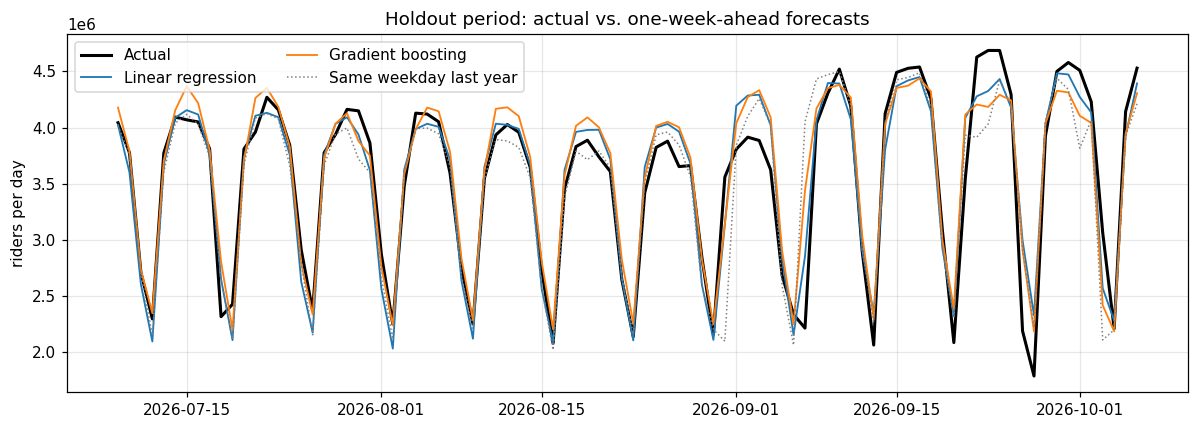

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y_te.index, y_te, color="black", lw=2, label="Actual")
ax.plot(y_te.index, preds["Linear regression"], lw=1.2, label="Linear regression")
ax.plot(y_te.index, preds["Gradient boosting"], lw=1.2, label="Gradient boosting")
ax.plot(y_te.index, preds["Baseline: same weekday last year"], lw=1, ls=":", color="gray",
        label="Same weekday last year")
ax.set_title("Holdout period: actual vs. one-week-ahead forecasts")
ax.set_ylabel("riders per day"); ax.legend(ncol=2)
plt.tight_layout(); plt.savefig(OUT_DIR / "holdout_forecast.png", dpi=150); plt.show()

## 6. Where do the models fail?
Aggregate error can hide the days that matter. Splitting the holdout by day type shows whether holidays and weekends drive the error.

In [9]:
day_type = np.where(test_df["is_holiday"] == 1, "holiday",
            np.where(test_df["dow"] >= 5, "weekend", "weekday"))

err = pd.DataFrame({
    name: (np.abs((y_te - p) / y_te) * 100) for name, p in preds.items()
})
err["day_type"] = day_type

by_type = err.groupby("day_type").agg(["mean"]).round(1)
by_type.columns = [c[0] for c in by_type.columns]
counts = pd.Series(day_type).value_counts().rename("n_days")
by_type = by_type.join(counts)
by_type.to_csv(OUT_DIR / "results_by_day_type.csv")
print("MAPE (%) by day type on the holdout:")
by_type

MAPE (%) by day type on the holdout:


,Baseline: same weekday last week,Baseline: same weekday last year,Linear regression,Gradient boosting,n_days
day_type,,,,,
holiday,61.0,83.4,29.0,55.6,1
weekday,5.0,4.5,3.9,4.5,63
weekend,10.0,8.4,9.2,7.6,26


## 7. What does the gradient-boosting model rely on?
Permutation importance measures how much MAE increases on the holdout when one feature is shuffled. A bigger increase means the model depends more on that feature.

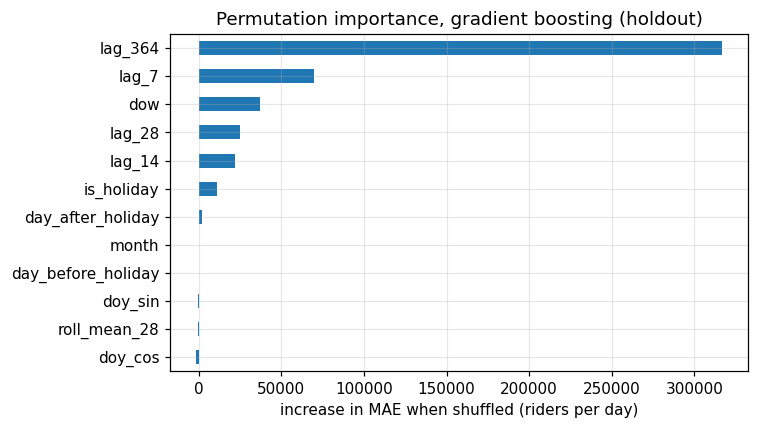

In [10]:
pi = permutation_importance(
    fitted["Gradient boosting"], X_te, y_te, n_repeats=15,
    scoring="neg_mean_absolute_error", random_state=RANDOM_STATE,
)
imp = (pd.Series(pi.importances_mean, index=FEATURES)
         .sort_values())
fig, ax = plt.subplots(figsize=(7, 4))
imp.plot.barh(ax=ax)
ax.set_xlabel("increase in MAE when shuffled (riders per day)")
ax.set_title("Permutation importance, gradient boosting (holdout)")
plt.tight_layout(); plt.savefig(OUT_DIR / "feature_importance.png", dpi=150); plt.show()

## 8. Summary
The cell below prints the headline comparison from the results above.

In [11]:
best = holdout.index[0]
naive = holdout.loc["Baseline: same weekday last week"]
print(f"Best model on the {HOLDOUT_DAYS}-day holdout: {best}")
print(f"  MAE {holdout.loc[best, 'MAE']:,.0f} riders/day, MAPE {holdout.loc[best, 'MAPE_%']:.1f}%")
print(f"  vs. same-weekday-last-week: MAE {naive['MAE']:,.0f}, MAPE {naive['MAPE_%']:.1f}%")
print(f"  MAE change vs. that baseline: {(holdout.loc[best, 'MAE'] / naive['MAE'] - 1) * 100:+.1f}%")

g, l = holdout.loc["Gradient boosting"], holdout.loc["Linear regression"]
print(f"Gradient boosting vs. linear regression (MAE): {(g['MAE'] / l['MAE'] - 1) * 100:+.1f}%")

Best model on the 90-day holdout: Linear regression
  MAE 178,249 riders/day, MAPE 5.7%
  vs. same-weekday-last-week: MAE 226,062, MAPE 7.1%
  MAE change vs. that baseline: -21.2%
Gradient boosting vs. linear regression (MAE): +7.5%


## Limitations
- One NYC system-wide series. It says nothing about other cities or individual stations.
- The data are daily estimates that the MTA can revise; results will shift slightly as the dataset updates.
- Only federal holidays are modeled. Blizzards, strikes, parades, and other local events are unmodeled and show up as large errors.
- Weather and economic drivers are not included. Adding them would be the natural next step.
- The 2020-2021 pandemic period is excluded from training because the weekly pattern was structurally different.